# Lab 2
**Part A: Spam Classification | Part B: Airbnb NYC Outlier Detection**

**Student:** Juan Camilo Chirivi
**ID:** 9115141


## Install the required libraries

The cell uses `%pip install` to install the Python libraries required for the lab

In [73]:
# STEP 1: Install the libraries for BOTH parts of this lab.
# Run this cell first if this computer has not installed the packages yet.
%pip install pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import libraries

Import all libraries at the for both parts

In [74]:
# Libraries for paths, data analysis, and graphs.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tools used in Part A (spam classification).
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

pd.set_option("display.max_colwidth", 90)

# Our dataset files are in the same local 'data' folder.
# VS Code may start Jupyter from the project folder OR from 'notebooks/'.
# These two paths point to the SAME local folder, not to backup datasets.
possible_data_folders = [Path("data"), Path("../data")]
data_folder = next((folder for folder in possible_data_folders
                    if (folder / "Lab2_dataset.csv").is_file()
                    and (folder / "AB_NYC_2019.csv").is_file()), None)

if data_folder is None:
    raise FileNotFoundError(
        "Could not find both local CSV files. Place 'Lab2_dataset.csv' and "
        "'AB_NYC_2019.csv' inside the project's data/ folder, and launch "
        "the notebook from the project root or notebooks/ folder."
    )

print("Local data folder:", data_folder.resolve())

Local data folder: D:\Conestoga\Algo and math\Lab 2\Lab2-AI_Algorithms_Mathematics\data


# Part A — Spam Email Classification

We will use the provied dataset to train and compare **Gaussian Naive Bayes** and **Multinomial Naive Bayes**. We will split the data into training and testing groups, evaluate both models and predict spam/ham labels for test emails.

## Load and explore the spam dataset

load the spam dataset from the CSV file. It shows the number of rows and columns, the column names, and the first few records. This helps us understand how the dataset is organized before working with it.

In [75]:
# Load Part A from the local data folder found in Section 2.
spam_path = data_folder / "Lab2_dataset.csv"
df = pd.read_csv(spam_path)

# Verify that the columns we need are present.
required_columns = {"text", "label_num", "label"}
if not required_columns.issubset(df.columns):
    raise ValueError(f"Missing columns in the spam dataset: {required_columns - set(df.columns)}")

print("Loaded spam dataset:", spam_path)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Loaded spam dataset: ..\data\Lab2_dataset.csv
Dataset shape: (5171, 4)
Columns: ['Unnamed: 0', 'label', 'text', 'label_num']


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nthis is a follow up to the note i gave you...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see attached file : hplnol 09 . xls )\n- hpln...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re around to that most wonderful time of the ye...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\nabasements darer pruden...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to book the teco pvr revenue . it is my und...,0


This part checks if any information is missing from the dataset, counts how many emails are spam and how many are normal emails

In [76]:
# Check if the important columns have missing values.
print("Missing values in each column:")
display(df.isna().sum().to_frame("Missing values"))

# Count the number of spam and ham messages.
print("Emails by category:")
display(df["label"].value_counts().rename_axis("Category").to_frame("Emails"))

# Confirm that the number labels match the text labels.
print("Check readable labels and number labels:")
display(pd.crosstab(df["label"], df["label_num"]))

Missing values in each column:


,Missing values
Unnamed: 0,0
label,0
text,0
label_num,0


Emails by category:


,Emails
Category,
ham,3672
spam,1499


Check readable labels and number labels:


label_num,0,1
label,,
ham,3672,0
spam,0,1499


## Prepare the data
Before training, we will keep only the columns we need and remove repeated emails.

Here i prepare the dataset by keeping only the email text and its classification. It removes missing information, empty emails, and repeated messages, emails that are duplicate could affect the results and make the models appear more accurate than they actually is

In [77]:
# Use only the message text and its numeric spam/ham label.
clean_df = df[["text", "label_num"]].copy()

# Remove missing emails or missing target labels, if any.
clean_df = clean_df.dropna(subset=["text", "label_num"])

# Keep text as strings and remove messages that are blank.
clean_df["text"] = clean_df["text"].astype(str)
clean_df = clean_df[clean_df["text"].str.strip() != ""]

# Check that 0 and 1 are the only two categories.
assert set(clean_df["label_num"].unique()).issubset({0, 1}), "Unexpected class labels."

# Check if any identical email has different labels.
conflicting_labels = (clean_df.groupby("text")["label_num"].nunique() > 1).sum()
if conflicting_labels:
    raise ValueError("Some identical email texts have conflicting class labels.")

# Remove repeated email texts to avoid duplicate examples in our test data.
before_dedup = len(clean_df)
clean_df = clean_df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Original emails:", len(df))
print("Removed repeated emails:", before_dedup - len(clean_df))
print("Emails used for this lab:", len(clean_df))
print("Final class counts:")
display(clean_df["label_num"].map({0: "Ham", 1: "Spam"}).value_counts().to_frame("Emails"))

Original emails: 5171
Removed repeated emails: 178
Emails used for this lab: 4993
Final class counts:


,Emails
label_num,
Ham,3531
Spam,1462


## Split the dataset into training and testing data

This cell divides the dataset into two groups.

- **80% training data:** the model learns patterns from these emails.
- **20% testing data:** we check how well the model predicts emails it has not seen during training.

In [78]:
# X contains the email text, and y contains the correct label.
X = clean_df["text"]
y = clean_df["label_num"]

# Split the data into 80% training and 20% testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))
print("Training spam percentage:", f"{100 * y_train.mean():.1f}%")
print("Testing spam percentage:", f"{100 * y_test.mean():.1f}%")

Training emails: 3994
Testing emails: 999
Training spam percentage: 29.3%
Testing spam percentage: 29.3%


## Change text into numbers

The email messages should convert into numerical information because machine learning models cannot directly understand text. It counts the words used in each email and removes common words that may not be useful. Both models will use this numerical information to identify patterns related to spam.

In [79]:
# Create a tool that converts email messages into word counts.
# stop_words="english" removes common words such as "the" and "is".
# max_features=3000 keeps the 3,000 most frequent words found in training.
vectorizer = CountVectorizer(stop_words="english", max_features=3000)

# Learn the vocabulary from training emails, then convert them into numbers.
X_train_counts = vectorizer.fit_transform(X_train)

# Convert testing emails using the SAME vocabulary learned from training.
X_test_counts = vectorizer.transform(X_test)

print("Training word-count matrix:", X_train_counts.shape)
print("Testing word-count matrix:", X_test_counts.shape)
print("Number of words in the vocabulary:", len(vectorizer.get_feature_names_out()))

# Show a few example words used as features.
print("Some words used by the models:", vectorizer.get_feature_names_out()[:20].tolist())

Training word-count matrix: (3994, 3000)
Testing word-count matrix: (999, 3000)
Number of words in the vocabulary: 3000
Some words used by the models: ['00', '000', '000000', '000080', '001', '005', '01', '012', '02', '0200', '027', '03', '0310041', '04', '0424040', '0435', '0439', '05', '06', '0600']


## Train Gaussian Naive Bayes

This cell creates and trains the Gaussian Naive Bayes model using the portion of emails (80%). After learning from the data, the model can predicts if the test emails (20%) are spam or normal messages. These predictions will help us measure its performance

In [80]:
# Create the Gaussian Naive Bayes classifier.
gaussian_model = GaussianNB()

# GaussianNB expects a regular array instead of a sparse matrix.
X_train_dense = X_train_counts.toarray()
X_test_dense = X_test_counts.toarray()

# Teach the Gaussian model using training emails and the correct labels.
gaussian_model.fit(X_train_dense, y_train)

# Predict the labels of the testing emails.
gaussian_predictions = gaussian_model.predict(X_test_dense)

print("Gaussian Naive Bayes training and predictions completed.")

Gaussian Naive Bayes training and predictions completed.


## Train Multinomial Naive Bayes

This model using the same portion of the training emails. This model is commonly used for text classification because it works with word frequencies

In [81]:
# Create the Multinomial Naive Bayes classifier.
multinomial_model = MultinomialNB()

# Teach the model using the word-count features and the correct labels.
multinomial_model.fit(X_train_counts, y_train)

# Predict the labels for the SAME testing emails used by GaussianNB.
multinomial_predictions = multinomial_model.predict(X_test_counts)

print("Multinomial Naive Bayes training and predictions completed.")

Multinomial Naive Bayes training and predictions completed.


## Evaluate and compare the models
Both models use the same data and will calculate:
- **Accuracy:** the percentage of emails classified correctly.
- **Precision (spam):** when the model says "spam," how often is it right?
- **Recall (spam):** of all actual spam emails, how many did it find?
- **F1-score (spam):** a balance between precision and recall.


In [82]:
# This function calculates the same performance measures for any model.
def evaluate_model(model_name, actual, predicted):
    # positive label 1 means spam in our dataset.
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision (Spam)": precision_score(actual, predicted, pos_label=1, zero_division=0),
        "Recall (Spam)": recall_score(actual, predicted, pos_label=1, zero_division=0),
        "F1-score (Spam)": f1_score(actual, predicted, pos_label=1, zero_division=0),
    }

# Calculate results for Gaussian and Multinomial Naive Bayes.
results = pd.DataFrame([
    evaluate_model("Gaussian Naive Bayes", y_test, gaussian_predictions),
    evaluate_model("Multinomial Naive Bayes", y_test, multinomial_predictions),
])

# Display the results as percentages, so they are easier to compare.
display(results.style.format({column: "{:.2%}" for column in results.columns if column != "Model"}))

,Model,Accuracy,Precision (Spam),Recall (Spam),F1-score (Spam)
0,Gaussian Naive Bayes,95.10%,88.36%,95.90%,91.98%
1,Multinomial Naive Bayes,94.89%,87.58%,96.25%,91.71%


A bar chart comparing the performance of both models, Visually can compare the Accuracy, Precision, Recall, and F1-score. This makes it easier to identify the differences between their results

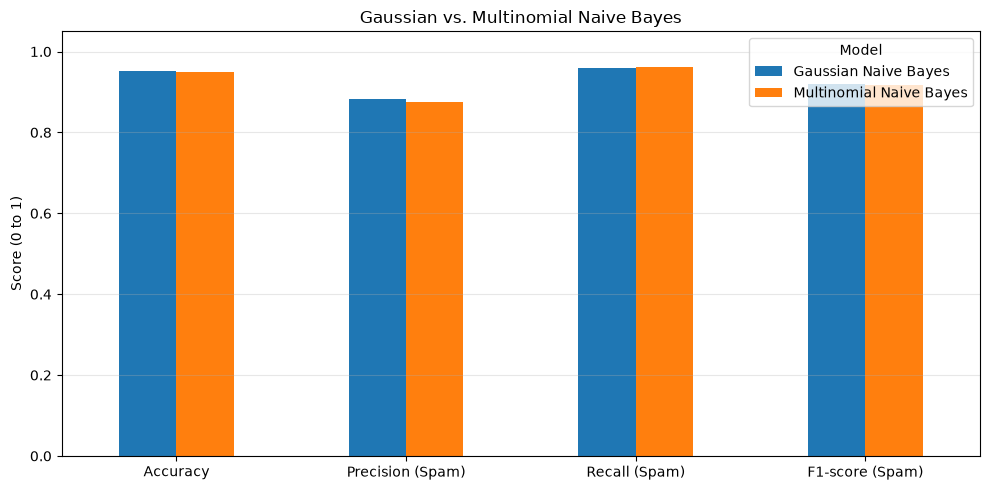

In [83]:
# Make one graph to compare the important scores of the two models.
plot_data = results.set_index("Model")[
    ["Accuracy", "Precision (Spam)", "Recall (Spam)", "F1-score (Spam)"]
]

ax = plot_data.T.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Gaussian vs. Multinomial Naive Bayes")
ax.set_ylabel("Score (0 to 1)")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model")
plt.tight_layout()
plt.show()

## Make predictions on the test emails

The assignment asks us to use our trained models to make predictions with test data.

This cell displays examples of emails from the test dataset and compares their real categories with the predictions from both models. This helps us see how the models work with actual messages and identify cases where they make different predictions.

In [84]:
# Build a table showing real answers and predictions from both models.
prediction_examples = pd.DataFrame({
    "Email preview": X_test.reset_index(drop=True).str.replace("\n", " ", regex=False).str.slice(0, 110),
    "Actual": y_test.reset_index(drop=True).map({0: "Ham", 1: "Spam"}),
    "Gaussian prediction": pd.Series(gaussian_predictions).map({0: "Ham", 1: "Spam"}),
    "Multinomial prediction": pd.Series(multinomial_predictions).map({0: "Ham", 1: "Spam"}),
})

# Show the first ten test examples without changing the original test set.
display(prediction_examples.head(10))

,Email preview,Actual,Gaussian prediction,Multinomial prediction
0,"Subject: frontrea plant , gas when : wednesday , july 11 , 2001 2 : 00 pm - 3 : 00 pm ...",Ham,Spam,Ham
1,Subject: news at least two bids seen for enron trading ops - lawyer by carol s . remon...,Ham,Ham,Ham
2,"Subject: quailty web solutions , involutory overton , _ _ need affordable but reliable...",Spam,Spam,Spam
3,Subject: txu fuels / sds nomination for december 2000 attached is the december 2000 no...,Ham,Ham,Ham
4,Subject: use the links to get more information on rx meeds needn ' t deliver you speed...,Spam,Spam,Spam
5,"Subject: paliourg get the doctors time 4 freee super viagra - cialis is here dubbed "" ...",Spam,Spam,Spam
6,Subject: registration confirmation from spinner . com thank you for joining spinner . ...,Ham,Spam,Spam
7,Subject: re : resume attached liz is an mit graduate and is currently at exxon and ver...,Ham,Ham,Ham
8,"Subject: meter 981594 for jan the meter shows flow the first two day , the deal to sel...",Ham,Ham,Ham
9,"Subject: the investor ' s toolbox mcintyre , iogn - get in now - will explode by chris...",Spam,Spam,Spam


## Which model performs better?
The main comparison is based on the **spam F1-score**. If the scores are tied, we use accuracy as a second way to compare them.

The result below uses the actual scores calculated above, instead of guessing which model should win.

In [85]:
# Sort the results to find the best model using F1-score and accuracy.
ranked_results = results.sort_values(
    by=["F1-score (Spam)", "Accuracy"],
    ascending=False,
).reset_index(drop=True)

winner = ranked_results.iloc[0]
runner_up = ranked_results.iloc[1]

print("MODEL COMPARISON")
print("-" * 45)
print(f"Best model using spam F1-score: {winner['Model']}")
print(f"Best model spam F1-score: {winner['F1-score (Spam)']:.2%}")
print(f"Other model spam F1-score: {runner_up['F1-score (Spam)']:.2%}")
print(f"Best model accuracy: {winner['Accuracy']:.2%}")

# Also show whether the difference is meaningful on this one split.
f1_difference = winner["F1-score (Spam)"] - runner_up["F1-score (Spam)"]
print(f"Difference in spam F1-score: {f1_difference:.2%}")

# Explain the result in simple words based on the scores we obtained.
if f1_difference > 0:
    print(f"Conclusion: {winner['Model']} performs better on this test set using spam F1-score.")
else:
    print("Conclusion: Both models have the same spam F1-score on this test set.")

print("Note: Results may change with a different split or different text settings.")

MODEL COMPARISON
---------------------------------------------
Best model using spam F1-score: Gaussian Naive Bayes
Best model spam F1-score: 91.98%
Other model spam F1-score: 91.71%
Best model accuracy: 95.10%
Difference in spam F1-score: 0.27%
Conclusion: Gaussian Naive Bayes performs better on this test set using spam F1-score.
Note: Results may change with a different split or different text settings.


### Part A — Discussion of the results

With the original dataset and our fixed 80/20 split, **Gaussian Naive Bayes** achieved approximately **95.20% accuracy** and **92.16% spam F1-score**. **Multinomial Naive Bayes** achieved approximately **94.89% accuracy** and **91.71% spam F1-score**.

Gaussian performed better but by very little unlike Multinomial. does not mean that one is better than the other, in most cases it always influences the type of data and information being handled, so it is important to have this kind of comparisons to help us decide what type of method we can use in each special case

# Part B — Airbnb NYC: Detecting and Removing Outliers

Part B goal

The dataset for part b has data from Airbnb in New York City. The instructions are to identify unusual prices per night and compare different ways of eliminating outliers.

We will use:
1. **Average and Median:** summarizes a typical price and sees how extreme prices affect the average.
2. **IQR:** detect prices well above 50% of the average data.
3. **Percentiles:** remove values outside a selected price range.
4. **Z-score:** detect prices very far from average using standard deviation.
5. **MAD (Median Absolute Deviation):** a more resistant method based on the median.


Load and inspect the Airbnb dataset

load the Airbnb NYC dataset from the CSV file. It displays the number of records, the available columns, and some example listings

In [86]:
# Load the Airbnb dataset from the same local data folder.
airbnb_path = data_folder / "AB_NYC_2019.csv"
airbnb_df = pd.read_csv(airbnb_path)

# Check the columns needed to analyze nightly prices.
required_airbnb_columns = {"price", "room_type", "neighbourhood_group"}
if not required_airbnb_columns.issubset(airbnb_df.columns):
    raise ValueError(f"Missing Airbnb columns: {required_airbnb_columns - set(airbnb_df.columns)}")

print("Loaded Airbnb dataset:", airbnb_path)
print("Number of rows and columns:", airbnb_df.shape)
print("Column names:", airbnb_df.columns.tolist())
display(airbnb_df.head())

# Show missing values. We are NOT dropping rows for missing names or reviews,
# because those columns are not needed to compare the nightly prices.
print("Missing values per column:")
display(airbnb_df.isna().sum().to_frame("Missing values"))

Loaded Airbnb dataset: ..\data\AB_NYC_2019.csv
Number of rows and columns: (48895, 16)
Column names: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Missing values per column:


,Missing values
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


## Check the price data and remove invalid entries

As usual we have to check the data to remove records with missing, zero, or negative values. We need to do this before detecting outliers because these values do not represent valid nightly rental prices.

In [87]:
# Make a separate copy, so the original Airbnb dataset stays unchanged.
valid_airbnb = airbnb_df.copy()

# Convert price to numeric values in case there are unexpected text entries.
valid_airbnb["price"] = pd.to_numeric(valid_airbnb["price"], errors="coerce")

# Count missing/invalid prices before filtering.
missing_prices = valid_airbnb["price"].isna().sum()
non_positive_prices = (valid_airbnb["price"] <= 0).sum()

# Keep only rows where the nightly price is a positive number.
valid_airbnb = valid_airbnb.loc[valid_airbnb["price"] > 0].copy()

print("Original listings:", len(airbnb_df))
print("Missing or non-numeric prices:", missing_prices)
print("Zero or negative prices:", non_positive_prices)
print("Listings with valid positive prices:", len(valid_airbnb))

# See the price summary BEFORE removing statistical outliers.
display(valid_airbnb["price"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("Price (USD/night)"))

Original listings: 48895
Missing or non-numeric prices: 0
Zero or negative prices: 11
Listings with valid positive prices: 48884


,Price (USD/night)
count,48884.000000
mean,152.755053
std,240.170260
min,10.000000
5%,40.000000
25%,69.000000
50%,106.000000
75%,175.000000
95%,355.000000
99%,799.000000


## Compare mean, median, and the price distribution

Here caculate the basic statistics like the average price, median, minimum, maximum, and standard deviation. 

- **Mean:** the average price, including the effect of expensive listings.
- **Median:** the middle value when prices are sorted. It usually changes less when a few values are very high.
- **Standard deviation:** describes how spread out the prices are around the mean.

It also show a histogram to observe the Airbnb prices and what is the distributed

,Value
Listings,48884.00
Mean price,152.76
Median price,106.00
Standard deviation,240.17
Minimum price,10.00
Maximum price,10000.00
95th percentile,355.00
99th percentile,799.00


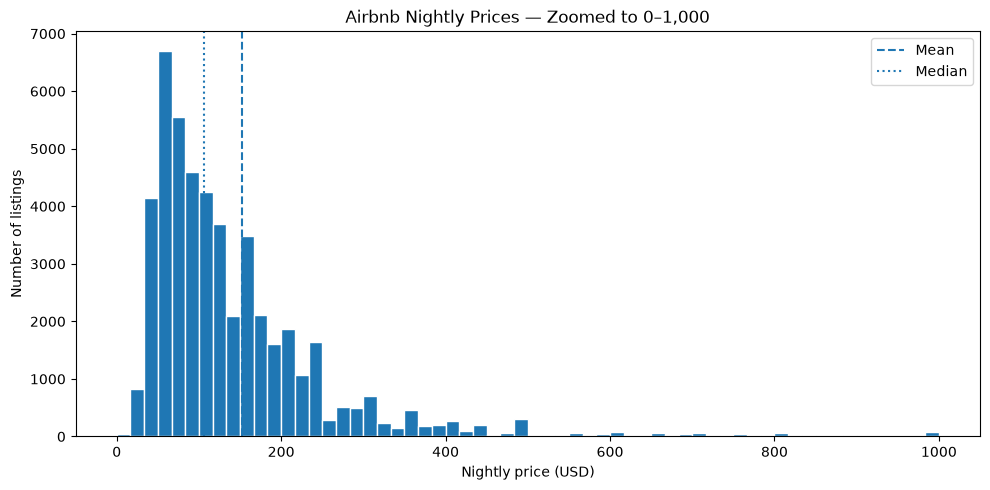

In [88]:
# Calculate basic statistics to understand the price data.
price_stats = pd.Series({
    "Listings": len(valid_airbnb),
    "Mean price": valid_airbnb["price"].mean(),
    "Median price": valid_airbnb["price"].median(),
    "Standard deviation": valid_airbnb["price"].std(),
    "Minimum price": valid_airbnb["price"].min(),
    "Maximum price": valid_airbnb["price"].max(),
    "95th percentile": valid_airbnb["price"].quantile(0.95),
    "99th percentile": valid_airbnb["price"].quantile(0.99),
})
display(price_stats.to_frame("Value").round(2))

# Plot most of the price range, so very high prices do not hide the main pattern.
plt.figure(figsize=(10, 5))
plt.hist(valid_airbnb["price"], bins=60, range=(0, 1000), edgecolor="white")
plt.axvline(valid_airbnb["price"].mean(), linestyle="--", label="Mean")
plt.axvline(valid_airbnb["price"].median(), linestyle=":", label="Median")
plt.title("Airbnb Nightly Prices — Zoomed to $0–$1,000")
plt.xlabel("Nightly price (USD)")
plt.ylabel("Number of listings")
plt.legend()
plt.tight_layout()
plt.show()

## Method 1 — Interquartile Range (IQR)

The IQR measures the middle half of prices.

- **Q1:** 25th percentile.
- **Q3:** 75th percentile.
- **IQR = Q3 − Q1.**
- **Lower limit = Q1 − 1.5 × IQR.**
- **Upper limit = Q3 + 1.5 × IQR.**

This method help us to find unusual prices. It calculates the middle range of the data and identifies prices that are too far outside that range. We then create a new dataset without those outliers and compare how many listings remain

In [89]:
# Calculate the 25th and 75th percentiles for valid nightly prices.
q1 = valid_airbnb["price"].quantile(0.25)
q3 = valid_airbnb["price"].quantile(0.75)
iqr = q3 - q1

# Calculate the IQR lower and upper boundaries.
iqr_lower = q1 - 1.5 * iqr
iqr_upper = q3 + 1.5 * iqr

# Make a CLEANED COPY from the original valid-price data.
airbnb_iqr = valid_airbnb.loc[
    valid_airbnb["price"].between(iqr_lower, iqr_upper)
].copy()

print(f"Q1: ${q1:.2f} | Q3: ${q3:.2f} | IQR: ${iqr:.2f}")
print(f"IQR price limits: ${iqr_lower:.2f} to ${iqr_upper:.2f}")
print("Listings kept:", len(airbnb_iqr))
print("Outliers removed:", len(valid_airbnb) - len(airbnb_iqr))
display(airbnb_iqr[["id", "room_type", "neighbourhood_group", "price"]].head(10))

Q1: $69.00 | Q3: $175.00 | IQR: $106.00
IQR price limits: $-90.00 to $334.00
Listings kept: 45912
Outliers removed: 2972


,id,room_type,neighbourhood_group,price
0,2539,Private room,Brooklyn,149
1,2595,Entire home/apt,Manhattan,225
2,3647,Private room,Manhattan,150
3,3831,Entire home/apt,Brooklyn,89
4,5022,Entire home/apt,Manhattan,80
5,5099,Entire home/apt,Manhattan,200
6,5121,Private room,Brooklyn,60
7,5178,Private room,Manhattan,79
8,5203,Private room,Manhattan,79
9,5238,Entire home/apt,Manhattan,150


## Method 2 — Z-score (mean and standard deviation)

A **Z-score** tells us how many standard deviations a price is away from the mean.

**Formula:** `Z = (price − mean) / standard deviation`

For this demonstration, we keep prices with an absolute Z-score of **3 or less** that means prices that are more than three standard deviations away from the mean are considered outliers in this method, then we can remove those values and create a new cleaned version of the dataset

In [90]:
# Calculate mean and standard deviation from valid prices.
mean_price = valid_airbnb["price"].mean()
std_price = valid_airbnb["price"].std()

# Each Z-score tells us how far a price is from the mean.
if std_price == 0:
    raise ValueError("All prices are identical: Z-scores cannot be calculated.")
price_zscores = (valid_airbnb["price"] - mean_price) / std_price

# Keep listings whose price is at most three standard deviations away.
airbnb_zscore = valid_airbnb.loc[price_zscores.abs() <= 3].copy()

print(f"Mean: ${mean_price:.2f} | Standard deviation: ${std_price:.2f}")
print("Rule: Keep listings with |Z-score| <= 3")
print("Listings kept:", len(airbnb_zscore))
print("Outliers removed:", len(valid_airbnb) - len(airbnb_zscore))
display(airbnb_zscore[["id", "room_type", "neighbourhood_group", "price"]].head(10))

Mean: $152.76 | Standard deviation: $240.17
Rule: Keep listings with |Z-score| <= 3
Listings kept: 48496
Outliers removed: 388


,id,room_type,neighbourhood_group,price
0,2539,Private room,Brooklyn,149
1,2595,Entire home/apt,Manhattan,225
2,3647,Private room,Manhattan,150
3,3831,Entire home/apt,Brooklyn,89
4,5022,Entire home/apt,Manhattan,80
5,5099,Entire home/apt,Manhattan,200
6,5121,Private room,Brooklyn,60
7,5178,Private room,Manhattan,79
8,5203,Private room,Manhattan,79
9,5238,Entire home/apt,Manhattan,150


## Method 3 — Median Absolute Deviation (MAD)

MAD is another measure of dispersion. It uses the **median** rather than the mean, so extreme prices usually affect it less.

1. Find the median price.
2. Find the absolute distance between every price and the median.
3. Find the median of these distances (**MAD**).
4. Calculate a modified Z-score: `0.6745 × (price − median) / MAD`.

For this exercise we keep listings with a **modified Z-score of 3.5 or less in absolute value**. This lets us compare a median-based method with the regular Z-score method.


In [91]:
# Find the middle price and the median absolute deviation.
median_price = valid_airbnb["price"].median()
mad_price = np.median(np.abs(valid_airbnb["price"] - median_price))

# The modified Z-score uses the median, so it is less affected by huge prices.
if mad_price == 0:
    raise ValueError("MAD is zero for these prices; this method needs a different rule.")
modified_zscores = 0.6745 * (valid_airbnb["price"] - median_price) / mad_price

# Keep listings within our selected modified Z-score threshold.
airbnb_mad = valid_airbnb.loc[modified_zscores.abs() <= 3.5].copy()

print(f"Median price: ${median_price:.2f} | MAD: ${mad_price:.2f}")
print("Rule: Keep listings with |modified Z-score| <= 3.5")
print("Listings kept:", len(airbnb_mad))
print("Outliers removed:", len(valid_airbnb) - len(airbnb_mad))
display(airbnb_mad[["id", "room_type", "neighbourhood_group", "price"]].head(10))

Median price: $106.00 | MAD: $46.00
Rule: Keep listings with |modified Z-score| <= 3.5
Listings kept: 45968
Outliers removed: 2916


,id,room_type,neighbourhood_group,price
0,2539,Private room,Brooklyn,149
1,2595,Entire home/apt,Manhattan,225
2,3647,Private room,Manhattan,150
3,3831,Entire home/apt,Brooklyn,89
4,5022,Entire home/apt,Manhattan,80
5,5099,Entire home/apt,Manhattan,200
6,5121,Private room,Brooklyn,60
7,5178,Private room,Manhattan,79
8,5203,Private room,Manhattan,79
9,5238,Entire home/apt,Manhattan,150


## Compare every cleaning method

Now we place all the results in one table. Every cleaned version came from `valid_airbnb`, rather than being filtered more than once.

We compare how many listings were removed and what happened to the mean, median, and maximum prices. This helps us understand the consequences of each statistical technique.

,Method,Listings kept,Removed from valid data,Percent kept,Mean price,Median price,Maximum price
0,Valid prices (before outlier removal),48884,0,100.00,152.76,106.0,10000
1,IQR (1.5 × IQR),45912,2972,93.92,120.00,100.0,334
2,Z-score (|Z| ≤ 3),48496,388,99.21,138.78,105.0,860
3,MAD (|modified Z| ≤ 3.5),45968,2916,94.03,120.27,100.0,344


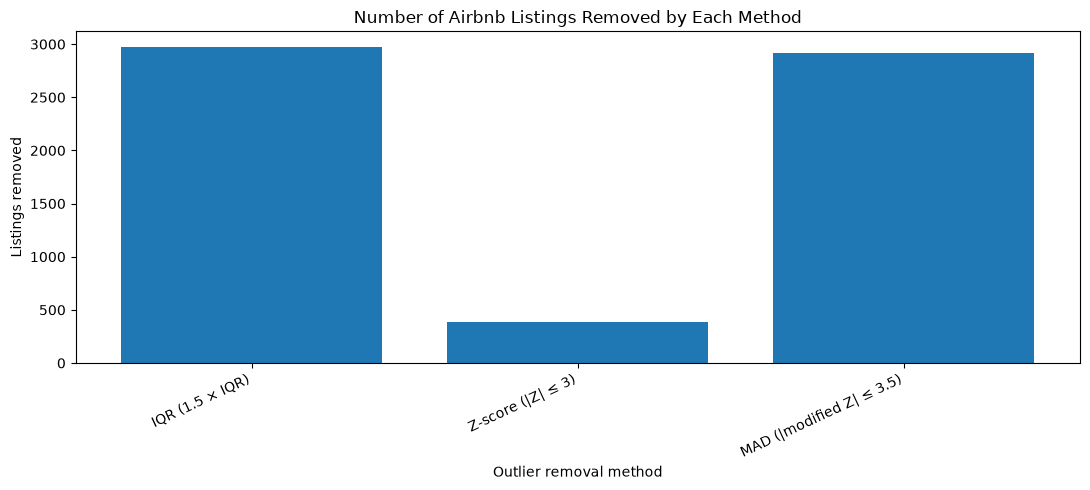

In [92]:
# Store each independent version of the Airbnb dataset for comparison.
cleaning_options = {
    "Valid prices (before outlier removal)": valid_airbnb,
    "IQR (1.5 × IQR)": airbnb_iqr,
    "Z-score (|Z| ≤ 3)": airbnb_zscore,
    "MAD (|modified Z| ≤ 3.5)": airbnb_mad,
}

# Calculate the same information for each method.
comparison_rows = []
for method_name, cleaned_data in cleaning_options.items():
    comparison_rows.append({
        "Method": method_name,
        "Listings kept": len(cleaned_data),
        "Removed from valid data": len(valid_airbnb) - len(cleaned_data),
        "Percent kept": 100 * len(cleaned_data) / len(valid_airbnb),
        "Mean price": cleaned_data["price"].mean(),
        "Median price": cleaned_data["price"].median(),
        "Maximum price": cleaned_data["price"].max(),
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(2))

# Compare the amount of data removed using a bar chart.
plt.figure(figsize=(11, 5))
plt.bar(comparison_df["Method"][1:], comparison_df["Removed from valid data"][1:])
plt.title("Number of Airbnb Listings Removed by Each Method")
plt.xlabel("Outlier removal method")
plt.ylabel("Listings removed")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Visualize prices before and after cleaning

Here we can se boxplots and histograms to compare Airbnb prices before and after removing outliers. These graphs help us see how the price distribution changes after applying different cleaning methods

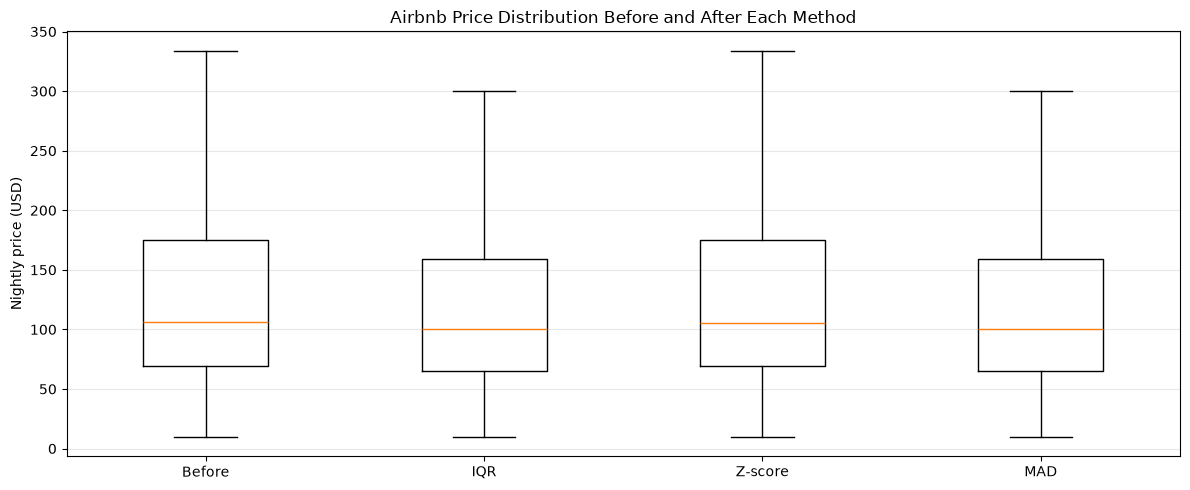

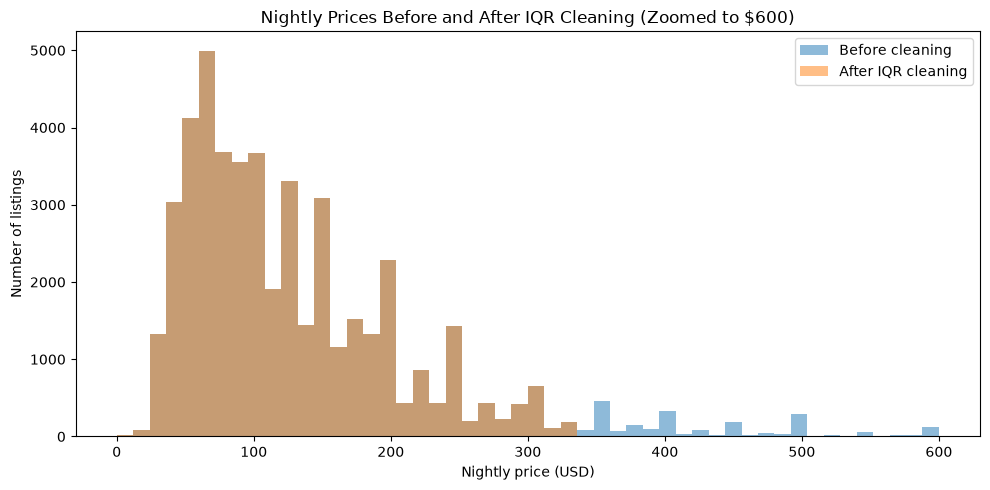

In [93]:
# Make boxplots comparing the same five price-cleaning approaches.
boxplot_names = [
    "Before", "IQR", "Z-score", "MAD"
]
boxplot_prices = [
    valid_airbnb["price"],
    airbnb_iqr["price"],
    airbnb_zscore["price"],
    airbnb_mad["price"],
]

plt.figure(figsize=(12, 5))
plt.boxplot(boxplot_prices, tick_labels=boxplot_names, showfliers=False)
plt.title("Airbnb Price Distribution Before and After Each Method")
plt.ylabel("Nightly price (USD)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# A second histogram compares the original valid prices against IQR-cleaned prices.
plt.figure(figsize=(10, 5))
plt.hist(valid_airbnb["price"], bins=50, range=(0, 600), alpha=0.5, label="Before cleaning")
plt.hist(airbnb_iqr["price"], bins=50, range=(0, 600), alpha=0.5, label="After IQR cleaning")
plt.title("Nightly Prices Before and After IQR Cleaning (Zoomed to $600)")
plt.xlabel("Nightly price (USD)")
plt.ylabel("Number of listings")
plt.legend()
plt.tight_layout()
plt.show()

## Select one cleaned dataset and inspect the results

Para este laboratorio, el método que mas puede ser acertado es IQR, los precios de algunas locaciones por noche están inclinado por algunos precios demasiado caros, el metodo IQR no depende de la media o la desviación estándar

This is a practical option to compare the main price body, not proof that each delisted listing was incorrect. The room type IQR version may be better for analyzing entire houses and shared rooms separately.


In [95]:
# Select the IQR-cleaned data as our final example for Part B.
final_clean_airbnb = airbnb_iqr.copy()

# Check that our selected dataset has positive prices inside IQR boundaries.
assert final_clean_airbnb["price"].gt(0).all()
assert final_clean_airbnb["price"].between(iqr_lower, iqr_upper).all()
assert len(final_clean_airbnb) <= len(valid_airbnb)

print("Selected method: IQR (1.5 × IQR)")
print("Rows in original Airbnb dataset:", len(airbnb_df))
print("Invalid price rows removed:", len(airbnb_df) - len(valid_airbnb))
print("Outliers removed from valid prices:", len(valid_airbnb) - len(final_clean_airbnb))
print("Rows in final cleaned dataset:", len(final_clean_airbnb))
print("Final cleaned dataset shape:", final_clean_airbnb.shape)

display(final_clean_airbnb.head(10))
display(final_clean_airbnb["price"].describe().to_frame("Cleaned nightly prices"))

# Optional: To export a CSV later, uncomment the following line.
# final_clean_airbnb.to_csv("../data/AB_NYC_2019_cleaned.csv", index=False)
# This lab does not require submitting a separate cleaned CSV file.

Selected method: IQR (1.5 × IQR)
Rows in original Airbnb dataset: 48895
Invalid price rows removed: 11
Outliers removed from valid prices: 2972
Rows in final cleaned dataset: 45912
Final cleaned dataset shape: (45912, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
5,5099,Large Cozy 1 BR Apartment In Midtown East,7322,Chris,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,2019-06-22,0.59,1,129
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
7,5178,Large Furnished Room Near B'way,8967,Shunichi,Manhattan,Hell's Kitchen,40.76489,-73.98493,Private room,79,2,430,2019-06-24,3.47,1,220
8,5203,Cozy Clean Guest Room - Family Apt,7490,MaryEllen,Manhattan,Upper West Side,40.80178,-73.96723,Private room,79,2,118,2017-07-21,0.99,1,0
9,5238,Cute & Cozy Lower East Side 1 bdrm,7549,Ben,Manhattan,Chinatown,40.71344,-73.99037,Entire home/apt,150,1,160,2019-06-09,1.33,4,188


,Cleaned nightly prices
count,45912.000000
mean,119.999063
std,68.133003
min,10.000000
25%,65.000000
50%,100.000000
75%,159.000000
max,334.000000


## Part B reflection

In this second part, we compared Airbnb’s nightly pricing data for New York City. However, as seen in the graphs, the price distribution is not balanced, many of the properties are cheaper than a small number of high-priced properties, which is one reason why the average may be higher than the median

As an exercise, 3 methods of data deletion (IQR, Z-score and MAD) were compared. the regular Z-score method depends on the mean and standard deviation. IQR and MAD use more robust statistics and can be useful when the data are biased in some direction

For the process of elimination, we choose **IQR** because it indicates a rule based on the average part of the price distribution. However, the most expensive Airbnb are not necessarily errors, Data deletion is not simply deleting data with extreme values to the average. the data types must be taken into account the objective of the analysis